# 03 · Models

Seven models plus their average, trained to rank each month's members by their chance of beating SPY
next month. **Every model is judged the way the strategy uses it:** each month, take its top 10, and
count how many beat SPY (precision), next to that month's base rate, plus their average excess return.

**Three stages, each on data the others never see:**
1. **Tuning** (2014–2019): 30 random settings per model (20 for the neural network), each scored on six
   successive years, training only on the years before. The best setting has the highest average
   yearly precision minus half its spread across the years.
2. **Comparison** (2020–2022): each tuned model, trained to November 2019, scored on three untouched
   years. The best one here is the **headline**, chosen before the test is looked at.
3. **Test** (2023 on, once): every candidate retrained to November 2022 and scored once.

The training itself runs as a separate step (it takes under two hours); this notebook reads its results.

> Numbers are a **preview** until the Alpha Vantage download of delisted companies is finished.

In [1]:
import json

import joblib
import pandas as pd

from sp500_momentum import config, nb, plots
from sp500_momentum.modeling import evaluate as ev
from sp500_momentum.modeling import prep, train
from sp500_momentum.modeling.models import SPECS

nb.setup()  # caps table output, silences info logs, applies the chart style (see sp500_momentum/nb.py)

## 1. The folds

Each training window stops a month before the period it's scored on (a row's result is next month's).

In [2]:
data = prep.load_model_data(pd.read_parquet(config.FEATURES_TABLE))
prep.describe_folds(data)

,train_from,train_to,score_from,score_to,train_rows,score_rows,score_beat_rate
fold,,,,,,,
cv_2014,2010-01-29,2013-11-29,2014-01-31,2014-12-31,16991,4672,0.5032
cv_2015,2010-01-29,2014-11-28,2015-01-30,2015-12-31,21656,4810,0.5008
cv_2016,2010-01-29,2015-11-30,2016-01-29,2016-12-30,26449,5060,0.5136
cv_2017,2010-01-29,2016-11-30,2017-01-31,2017-12-29,31490,5251,0.4908
cv_2018,2010-01-29,2017-11-30,2018-01-31,2018-12-31,36726,5404,0.5091
cv_2019,2010-01-29,2018-11-30,2019-01-31,2019-12-31,42115,5564,0.4824
validation,2010-01-29,2019-11-29,2020-01-31,2022-12-30,47667,17443,0.4998
test,2010-01-29,2022-11-30,2023-01-31,2026-09-30,65083,22557,0.4517


## 2. Tuning (2014–2019)

Each model's best setting, and how much tuning mattered: the best try against the median try. A large
gap on six years of data is a warning that the setting may suit those years by luck.

In [3]:
cv = pd.read_csv(train.CV_RESULTS)
best = ev.best_tries(cv)
best["label"] = [SPECS[m].label for m in best.index]
years = sorted(int(c.split("_")[1]) for c in cv if c.startswith("precision_2"))
show = [
    "label",
    "tries",
    "selection_score",
    "median_try_score",
    "precision",
    "base_rate",
    "lift",
    "yearly_min",
    "excess",
]
best[show].sort_values("selection_score", ascending=False)

,label,tries,selection_score,median_try_score,precision,base_rate,lift,yearly_min,excess
model,,,,,,,,,
xgb,"XGBoost, beat or not",30,0.5268,0.4638,0.5556,0.5000,0.0555,0.4750,0.0068
tree,Decision tree,30,0.5236,0.4891,0.5569,0.5000,0.0569,0.4583,0.0042
rf,Random forest,30,0.5195,0.4733,0.5389,0.5000,0.0389,0.4917,0.0018
xgb_rank,"XGBoost, ranking",30,0.5148,0.4701,0.5250,0.5000,0.0250,0.5000,0.0050
mlp,Neural network (MLP),20,0.5096,0.4842,0.5306,0.5000,0.0305,0.4667,0.0013
xgb_reg,"XGBoost, by how much",30,0.5017,0.4737,0.5222,0.5000,0.0222,0.4583,0.0062
logreg,Logistic regression,30,0.4854,0.4759,0.5000,0.5000,-0.0000,0.4667,-0.0010


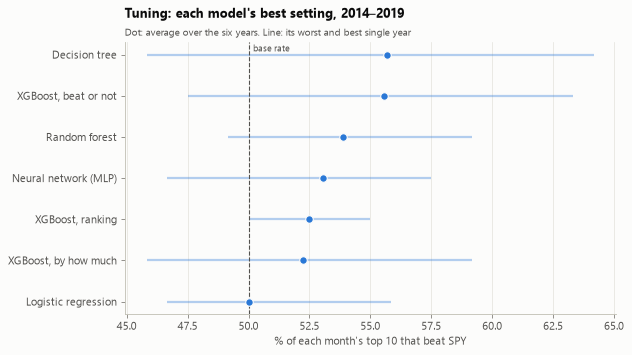

In [4]:
fig = plots.model_cv_chart(best, years, base_rate=best["base_rate"].mean())
plots.save(fig, "models_cv")

The chosen settings (the full record of every try is in `reports/model_cv_results.csv`):

In [5]:
pd.DataFrame({m: json.loads(p) for m, p in best["params"].items()}).T.fillna("")

,C,ranked,alpha,hidden_layer_sizes,learning_rate_init,max_depth,max_features,min_samples_leaf,n_estimators,colsample_bytree,learning_rate,min_child_weight,reg_lambda,subsample,huber_slope
logreg,0.0083,False,,,,,,,,,,,,,
mlp,,False,0.0000,[32],0.0020,,,,,,,,,,
rf,,False,,,,8,0.3827,20,594,,,,,,
tree,,False,,,,9,,500,,,,,,,
xgb,,True,,,,3,,,186,0.6663,0.0133,1.5533,0.1067,0.9212,
xgb_rank,,True,,,,6,,,124,0.6990,0.0587,169.6720,0.4611,0.5706,
xgb_reg,,False,,,,2,,,435,0.6193,0.0106,26.2775,11.1035,0.6798,0.0932


## 3. Comparison on 2020–2022 (the headline is chosen here)

Each tuned model trained up to November 2019, scored on three years no tuning has seen. The plain rules
are shown on the same months for reference.

In [6]:
table = pd.read_csv(train.COMPARISON)
cols = [
    "label",
    "precision",
    "base_rate",
    "lift",
    "excess",
    "yearly_min",
    "selection_score",
    "headline",
]
val = table[table["period"] == "validation"].sort_values("selection_score", ascending=False)
headline = table.loc[table["headline"], "model"].iloc[0]
print(f"Headline, chosen on 2020–2022: {table.loc[table['headline'], 'label'].iloc[0]}")
val[cols]

Headline, chosen on 2020–2022: XGBoost, by how much


,label,precision,base_rate,lift,excess,yearly_min,selection_score,headline
25,Rule: last month's top 10,0.5250,0.4993,0.0257,0.0085,0.4917,0.5043,False
28,Rule: 6-month top 10,0.5306,0.4991,0.0315,0.0074,0.4583,0.5041,False
16,"XGBoost, by how much",0.4917,0.4993,-0.0076,0.0120,0.4750,0.4827,True
4,Random forest,0.4861,0.4993,-0.0132,0.0015,0.4250,0.4635,False
13,"XGBoost, ranking",0.4750,0.4993,-0.0243,0.0128,0.4250,0.4573,False
1,Decision tree,0.4778,0.4993,-0.0215,0.0042,0.4417,0.4551,False
22,Average of the models,0.4722,0.4993,-0.0271,0.0007,0.4250,0.4548,False
10,"XGBoost, beat or not",0.4778,0.4993,-0.0215,-0.0069,0.4167,0.4503,False
19,Neural network (MLP),0.4833,0.4993,-0.0159,-0.0000,0.3500,0.4361,False
7,Logistic regression,0.4556,0.4993,-0.0437,0.0006,0.3500,0.4176,False


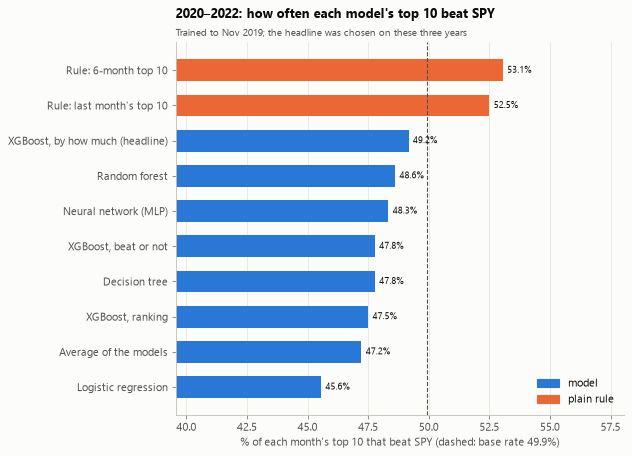

In [7]:
fig = plots.model_compare_chart(
    table,
    "validation",
    "2020–2022: how often each model's top 10 beat SPY",
    "Trained to Nov 2019; the headline was chosen on these three years",
)
plots.save(fig, "models_validation")

## 4. The test (2023 on, scored once)

Every candidate retrained up to November 2022 and scored once. Nothing was chosen on these months.

In [8]:
test = table[table["period"] == "test"].sort_values("precision", ascending=False)
test[cols]

,label,precision,base_rate,lift,excess,yearly_min,selection_score,headline
2,Decision tree,0.5400,0.4517,0.0883,0.0004,0.5167,0.5316,False
29,Rule: 6-month top 10,0.5289,0.4515,0.0774,0.0147,0.5083,0.5221,False
23,Average of the models,0.5067,0.4517,0.0550,0.0005,0.4583,0.4931,False
8,Logistic regression,0.4956,0.4517,0.0439,0.0027,0.4167,0.4728,False
20,Neural network (MLP),0.4711,0.4517,0.0194,0.0059,0.3917,0.4380,False
26,Rule: last month's top 10,0.4644,0.4516,0.0128,0.0045,0.4333,0.4404,False
5,Random forest,0.4556,0.4517,0.0039,-0.0012,0.3917,0.4286,False
11,"XGBoost, beat or not",0.4556,0.4517,0.0039,-0.0066,0.4333,0.4488,False
17,"XGBoost, by how much",0.4511,0.4517,-0.0006,-0.0083,0.4000,0.4287,True
14,"XGBoost, ranking",0.4289,0.4517,-0.0228,-0.0192,0.4083,0.4226,False


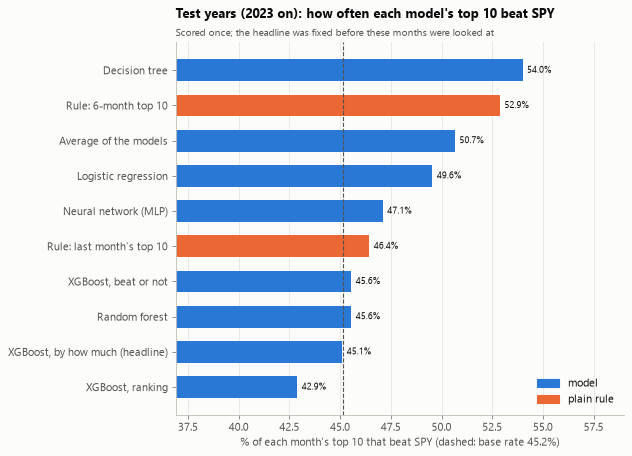

In [9]:
fig = plots.model_compare_chart(
    table,
    "test",
    "Test years (2023 on): how often each model's top 10 beat SPY",
    "Scored once; the headline was fixed before these months were looked at",
)
plots.save(fig, "models_test")

## 5. The rule columns for the simulations

Every candidate's out-of-sample scores (2014 on; each month scored by a model trained before it)
become `pred_<model>_top<N>` columns, the same form as the plain rule's, so the trading simulations
treat models and rules alike. The headline's top 10 at the latest scored month-end:

In [10]:
from sp500_momentum import backtest as bt

scores = pd.read_parquet(config.MODEL_SCORES)
names = [c for c in scores.columns if c not in ("date", "ticker", "price_ticker", "period")]
panel = bt.add_score_preds(pd.read_parquet(config.MONTHLY_PANEL), scores, names)
preds = [c for c in panel if c.startswith("pred_")]
last = scores["date"].max()
print(
    f"{len(preds)} model rule columns ({len(names)} candidates x top 1/5/10); scored months: "
    f"{scores['date'].min():%b %Y} to {last:%b %Y}"
)
panel.loc[(panel["date"] == last) & (panel[f"pred_{headline}_top10"] == 1), ["date", "ticker"]]

24 model rule columns (8 candidates x top 1/5/10); scored months: Jan 2014 to Sep 2026


,date,ticker
100464,2026-09-30,APP
100472,2026-09-30,AXON
100514,2026-09-30,CHTR
100611,2026-09-30,FICO
100613,2026-09-30,FISV
100632,2026-09-30,GLW
100713,2026-09-30,LULU
100832,2026-09-30,SMCI
100834,2026-09-30,SNDK
100927,2026-09-30,ZTS


## 6. What the headline model looks at

The share of the model's importance each input carries (for tree models, how much each feature
improves its splits). Importance shows what the model uses, not whether it's right to.

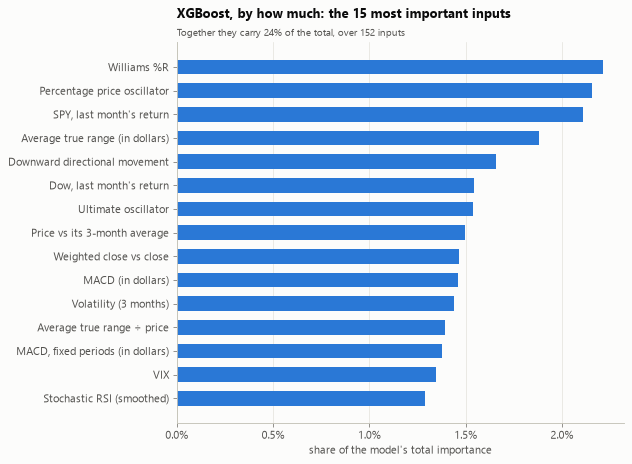

In [11]:
pipe = joblib.load(config.MODELS_DIR / f"{headline}.joblib") if headline in SPECS else None
imp = ev.feature_importance(pipe, data.X_raw.columns) if pipe is not None else None
if imp is None:
    print("The headline has no per-feature importance (an average or a neural network).")
else:
    share = imp.sort_values(ascending=False).head(15).sum() / imp.sum()
    fig = plots.importance_chart(
        imp,
        f"{SPECS[headline].label}: the 15 most important inputs",
        subtitle=f"Together they carry {share:.0%} of the total, over {len(imp)} inputs",
    )
    plots.save(fig, "models_importance")

## 7. What this means for the next steps

- **Tuning looked promising, but mostly by selection.** On 2014–2019, six of the seven models' best
  settings put more winners in their top 10 than the 50.0% base rate (logistic regression only matched
  it). But the *median* try of every model sat around the base rate (48.8–51.0%). Picking the best of
  20–30 tries on six years buys a few points that need not be real.
- **On 2020–2022, no model beat a random pick.** Every model's top 10 beat SPY less often than the
  49.9% base rate. Both plain rules beat it: 53.1% for the 6-month top 10 and 52.5% for last month's
  top 10. The headline, chosen on these years, is the XGBoost regressor ("by how much"), at 49.2%, the
  closest to the base rate and the steadiest year to year. Averaging the models didn't help (47.2%).
- **The test (2023 on) confirms it.** The headline's top 10 beat SPY 45.1% of months, against a
  base rate of 45.2%, and trailed SPY by 0.8% a month on average. The 6-month rule did better on both
  counts: 52.9%, and 1.5% a month ahead of SPY. The decision tree came top on the test (54.0%), but its
  picks gained almost nothing over SPY on average (+0.04% a month). Its 2020–22 score was below the base
  rate, so nothing seen before the test would have picked it. Choosing it now would be choosing on the
  test.
- **The headline spreads its attention thinly.** Its 15 most important inputs together carry about a
  quarter of the total, mostly short-term technical indicators and the market's last month. That is
  consistent with the exploratory analysis: no single feature has a strong, stable signal.
- **What this means for the simulations.** The trading backtests still run the headline model, as
  agreed, so that it gets judged on return, risk and costs next to the rules and SPY. The other
  candidates are shown alongside for reference, not chosen from. On this evidence, the plain 6-month
  rule is the one to beat, and these models do not beat it.
- All numbers are a **preview** until the Alpha Vantage download of delisted companies is finished.
